In [12]:
from mytools.data import vitems, read_h5
from mytools.plot import make_figure, plt, save_plot
from mytools.plot_custom import plot_pair_sep
from mytools.constant import C_HUB

In [10]:
parameters = {"axes.labelsize": 12, "axes.titlesize": 12, 'legend.fontsize': 'medium'}
plt.rcParams.update(parameters)

# plot galaxy pair separation distribution

In [17]:
pair_cat_file = '/work/home/liudy/data/sdss_catalog/crafts_skyarea_galaxy_pair_catalog.h5'
vitems(pair_cat_file)

Item: dist_ang
Type: Dataset
Shape: (257397,)
Dtype: float32
Attributes (1):
- description: Angular distance between the two galaxies in Mpc.
Item: dist_rad
Type: Dataset
Shape: (257397,)
Dtype: float32
Attributes (1):
- description: Radial distance between the two galaxies in Mpc.
Item: is_ra
Type: Dataset
Shape: (257397,)
Dtype: bool
Attributes (1):
- description: Boolean array indicating if the angular distance is along the RA axis.
Item: pos
Type: Dataset
Shape: (257397, 6)
Dtype: float32
Attributes (1):
- description: Positions of each galaxy pair. Saved as [ra1, dec1, freq1, ra2, dec2, freq2]. The units are degrees and MHz.


In [20]:
dist_ang, dist_rad = read_h5(pair_cat_file, ['dist_ang', 'dist_rad'])
sep_tra = dist_ang * C_HUB
sep_rad = dist_rad * C_HUB
sep_spa = (sep_tra**2 + sep_rad**2)**0.5

Transversal mean separation: 6.60 Mpc/h
Radial mean separation: 1.66 Mpc/h
Spatial mean separation: 6.88 Mpc/h
Plot saved to img_pair_sep_hist.pdf


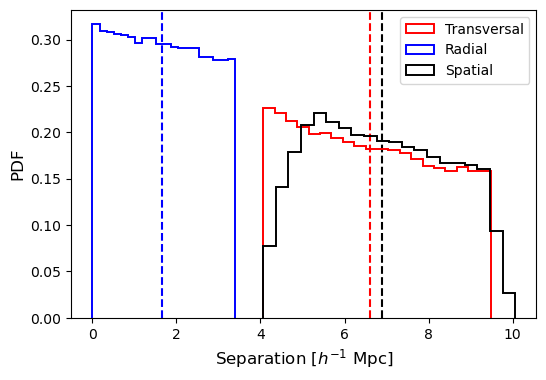

In [21]:
ax = plot_pair_sep([sep_tra, sep_rad, sep_spa])
figname = 'img_pair_sep_hist.pdf'
save_plot(ax, figname)